# KHALAF Team — Capstone Phase 2 (M4, M5, M8): CBIS-DDSM mass detection and segmentation
Continues the Phase 1 project (CBIS-DDSM, benign vs. malignant). Phase 2 finds masses on the **full mammogram** (M4), outlines them (M5) and serves the whole pipeline with the benign/malignant classifier (M8).

**How to run:** Runtime → Change runtime type → **T4 GPU**, then Runtime → **Run all**. Allow Google Drive access. The Kaggle key is read from Colab Secrets (`KAGGLE_USERNAME`, `KAGGLE_KEY`) or from an uploaded `kaggle.json`.
Every step saves its results to Google Drive and is skipped when its results already exist, so a stopped run continues where it left off.

## 0. Setup

In [1]:
import os, sys, json, time, glob, math, random, shutil, subprocess, hashlib, re
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
def sh(c, check=True):
    print('$', c); r = subprocess.run(c, shell=True)
    if check and r.returncode: raise RuntimeError(c)
sh(f'{sys.executable} -m pip install -q ultralytics==8.4.215 onnx onnxslim onnxruntime fastapi uvicorn python-multipart kaggle onnxscript', check=False)
if IN_COLAB:
    from google.colab import drive; drive.mount('/content/drive')
    D = Path('/content/drive/MyDrive'); cand = sorted(D.glob('*/KHALAF_Project')) + [D / 'KHALAF_Project']
    base = next((p.parent for p in cand if p.is_dir()), D)
    PROJ = base / 'KHALAF_CBIS_Phase2'
else:
    PROJ = Path('./KHALAF_CBIS_Phase2')
for s in ['detection', 'segmentation', 'deployment/models', 'deployment/service', 'deployment/results', 'figures', 'report']:
    (PROJ / s).mkdir(parents=True, exist_ok=True)
DATA = Path('/content/data') if IN_COLAB else Path('./data'); DATA.mkdir(parents=True, exist_ok=True)
RF = PROJ / 'results.json'
R = json.loads(RF.read_text()) if RF.exists() else {}
def save(): RF.write_text(json.dumps(R, indent=1, default=float))
import numpy as np, pandas as pd, cv2, torch
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
GPU = torch.cuda.is_available(); DEV = 0 if GPU else 'cpu'
import ultralytics, onnxruntime
R['env'] = dict(python=sys.version.split()[0], torch=torch.__version__, ultralytics=ultralytics.__version__, onnxruntime=onnxruntime.__version__,
                gpu=torch.cuda.get_device_name(0) if GPU else 'CPU only'); save()
CFG = dict(imgsz=640, long_side=1024, det_model='yolo11n-seg.pt', seg_model='yolo11n-seg.pt', epochs=10, batch=8, val_frac=0.2,
           conf_grid=[round(x, 2) for x in np.arange(0.05, 0.91, 0.05)], match_iou=0.3, cls_size=224, cls_epochs=6)
(PROJ / 'config.json').write_text(json.dumps(CFG, indent=1))
print(PROJ, R['env'])

$ /usr/bin/python3 -m pip install -q ultralytics==8.4.215 onnx onnxslim onnxruntime fastapi uvicorn python-multipart kaggle
Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
/content/drive/MyDrive/capston/KHALAF_CBIS_Phase2 {'python': '3.13.16', 'torch': '2.14.1+cu130', 'ultralytics': '8.4.215', 'onnxruntime': '1.32.0', 'gpu': 'Tesla T4'}


## Acceptance criteria (fixed before training)
The Phase 1 report did not list numeric criteria, so they are fixed here, before any Phase 2 model is trained.

In [2]:
AC = PROJ / 'acceptance_criteria.json'
if not AC.exists():
    AC.write_text(json.dumps({'fixed_on': time.strftime('%Y-%m-%d'), 'criteria': [
        dict(id='C1', name='Mass detection sensitivity (lesion level)', metric='det_recall_op', op='>=', thr=0.80, cond='test, IoU>=0.3, operating point'),
        dict(id='C2', name='False positives per image', metric='det_fppi_op', op='<=', thr=1.0, cond='test, operating point'),
        dict(id='C3', name='Detection mAP50', metric='det_map50', op='>=', thr=0.60, cond='test, conf 0.001'),
        dict(id='C4', name='Mass segmentation Dice (lesion pixels)', metric='seg_dice', op='>=', thr=0.70, cond='test, matched lesions'),
        dict(id='C5', name='Benign/malignant ROC-AUC on lesion crops', metric='cls_auc', op='>=', thr=0.75, cond='test, 224 px'),
        dict(id='C6', name='End-to-end p95 latency per image', metric='e2e_p95_ms', op='<=', thr=1500, cond='Colab, ONNX Runtime, HTTP incl. decode')]}, indent=1))
CRIT = json.loads(AC.read_text())['criteria']; print(pd.DataFrame(CRIT)[['id', 'name', 'op', 'thr']])

   id                                       name  op      thr
0  C1  Mass detection sensitivity (lesion level)  >=     0.80
1  C2                  False positives per image  <=     1.00
2  C3                            Detection mAP50  >=     0.60
3  C4     Mass segmentation Dice (lesion pixels)  >=     0.70
4  C5   Benign/malignant ROC-AUC on lesion crops  >=     0.75
5  C6           End-to-end p95 latency per image  <=  1500.00


## 1. Download CBIS-DDSM (Kaggle mirror used in Phase 1)

In [3]:
RAW = DATA / 'cbis_ddsm'
if not (RAW / 'csv').exists():
    for kj in [Path('/content/kaggle.json'), Path.home() / '.kaggle' / 'kaggle.json'] + ([D / 'kaggle.json', base / 'kaggle.json'] if IN_COLAB else []):   # kaggle.json uploaded to the Colab files panel (as in Phase 1)
        if kj.exists() and not os.environ.get('KAGGLE_KEY'):
            k = json.loads(kj.read_text()); os.environ['KAGGLE_USERNAME'] = k['username']; os.environ['KAGGLE_KEY'] = k['key']
    if IN_COLAB and not os.environ.get('KAGGLE_KEY'):
        try:
            from google.colab import userdata
            os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME'); os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
        except Exception:
            kj = None
            if kj is None:
                from google.colab import files; print('Upload kaggle.json'); files.upload(); kj = Path('kaggle.json')
            k = json.loads(Path(kj).read_text()); os.environ['KAGGLE_USERNAME'] = k['username']; os.environ['KAGGLE_KEY'] = k['key']
    sh(f'kaggle datasets download -d awsaf49/cbis-ddsm-breast-cancer-image-dataset -p {DATA} -q')
    sh(f'unzip -q -o {DATA}/cbis-ddsm-breast-cancer-image-dataset.zip -d {RAW}')
print(sorted(os.listdir(RAW)), len(glob.glob(str(RAW / 'jpeg' / '*'))), 'series folders')

$ kaggle datasets download -d awsaf49/cbis-ddsm-breast-cancer-image-dataset -p /content/data -q
$ unzip -q -o /content/data/cbis-ddsm-breast-cancer-image-dataset.zip -d /content/data/cbis_ddsm
['csv', 'jpeg'] 6774 series folders


## 2. Data: full mammograms, masses, ROI masks, patient-level split
Mass cases only. Each CSV row is one mass; its full mammogram and ROI mask are linked through the DICOM series UID in the path (the Phase 1 data-improvement plan asked for UID-based linking). Calcifications are left out: they are clusters of tiny dots, not single objects.

In [4]:
SPL = PROJ / 'detection' / 'cases.csv'
JPG = {p.name: sorted(p.glob('*.jpg')) for p in (RAW / 'jpeg').iterdir() if p.is_dir()}
def uid(path, k):
    parts = str(path).strip().split('/')
    return parts[k] if len(parts) > k else ''
def find_series(path):
    for k in (2, 1):
        u = uid(path, k)
        if u in JPG: return JPG[u]
    return []
if not SPL.exists():
    rows, excl = [], []
    for split, f in [('train', 'mass_case_description_train_set.csv'), ('test', 'mass_case_description_test_set.csv')]:
        df = pd.read_csv(RAW / 'csv' / f)
        for _, r in df.iterrows():
            full = find_series(r['image file path']); roi = find_series(r['ROI mask file path'])
            if len(full) != 1 or not roi: excl.append(dict(reason='no_match', patient=r['patient_id'])); continue
            fimg = full[0]; h, w = cv2.imread(str(fimg), cv2.IMREAD_GRAYSCALE).shape
            mask = None
            for m in roi:                       # the mask is the full-size, (nearly) binary file of the series
                im = cv2.imread(str(m), cv2.IMREAD_GRAYSCALE)
                if im is not None and im.shape == (h, w) and len(np.unique(im[::8, ::8])) <= 8: mask = m; break
            if mask is None: excl.append(dict(reason='mask_not_found_or_size_mismatch', patient=r['patient_id'])); continue
            rows.append(dict(orig_split=split, patient=r['patient_id'], image=str(fimg), mask=str(mask), w=w, h=h,
                             side=r['left or right breast'], view=r['image view'], abn=r['abnormality id'],
                             pathology=r['pathology'], malignant=int(r['pathology'] == 'MALIGNANT'), density=r.get('breast_density', r.get('breast density'))))
    cases = pd.DataFrame(rows)
    # patient-level split: train patients that also appear in test are removed; val = 20% of train patients (seed 42)
    test_p = set(cases.loc[cases.orig_split == 'test', 'patient'])
    overlap = cases[(cases.orig_split == 'train') & cases.patient.isin(test_p)]
    excl += [dict(reason='patient_overlap_train_test', patient=p) for p in overlap.patient]
    cases = cases.drop(overlap.index)
    trp = sorted(cases.loc[cases.orig_split == 'train', 'patient'].unique()); rng = random.Random(SEED); rng.shuffle(trp)
    valp = set(trp[:int(len(trp) * CFG['val_frac'])])
    cases['split'] = np.where(cases.orig_split == 'test', 'test', np.where(cases.patient.isin(valp), 'val', 'train'))
    cases.to_csv(SPL, index=False); pd.DataFrame(excl).to_csv(PROJ / 'detection' / 'excluded.csv', index=False)
cases = pd.read_csv(SPL); excl = pd.read_csv(PROJ / 'detection' / 'excluded.csv') if (PROJ / 'detection' / 'excluded.csv').stat().st_size > 1 else pd.DataFrame(columns=['reason'])
assert not (set(cases[cases.split == 'train'].patient) & set(cases[cases.split == 'test'].patient))
assert not (set(cases[cases.split == 'train'].patient) & set(cases[cases.split == 'val'].patient))
summ = cases.groupby('split').agg(masses=('patient', 'size'), images=('image', 'nunique'), patients=('patient', 'nunique'), malignant_share=('malignant', 'mean'))
R['m1'] = dict(split=summ.round(3).reset_index().to_dict('records'), excluded=excl.reason.value_counts().to_dict(), csv_rows=int(len(cases) + len(excl))); save()
print(summ, '\nexcluded:', R['m1']['excluded'])

       masses  images  patients  malignant_share
split                                           
test      325     311       186         0.375385
train     867     815       493         0.492503
val       216     199       123         0.439815 
excluded: {'mask_not_found_or_size_mismatch': 288}


## 3. Convert to YOLO format (boxes for M4, polygons for M5) and check visually

In [5]:
YD = DATA / 'cbis_yolo'
def contours_of(mask_path, sc):
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, None, fx=sc, fy=sc, interpolation=cv2.INTER_NEAREST) > 127
    cs, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [c for c in cs if cv2.contourArea(c) >= 16]
conv = {}
if not (YD / 'done.txt').exists():
    stats = dict(images=0, masses=0, multi_part_masks=0, empty_masks=0)
    for split in ['train', 'val', 'test']:
        for t in ['images', 'labels_det', 'labels_seg']: (YD / t / split).mkdir(parents=True, exist_ok=True)
        for img, g in cases[cases.split == split].groupby('image'):
            im = cv2.imread(img, cv2.IMREAD_GRAYSCALE); h, w = im.shape; sc = min(1.0, CFG['long_side'] / max(h, w))
            im = cv2.resize(im, (round(w * sc), round(h * sc)), interpolation=cv2.INTER_AREA); H, W = im.shape
            stem = Path(img).parent.name[-24:]; cv2.imwrite(str(YD / 'images' / split / f'{stem}.jpg'), im, [cv2.IMWRITE_JPEG_QUALITY, 92])
            det, seg = [], []
            for _, r in g.iterrows():
                cs = contours_of(r['mask'], sc)
                if not cs: stats['empty_masks'] += 1; continue
                if len(cs) > 1: stats['multi_part_masks'] += 1
                c = max(cs, key=cv2.contourArea); x, y, bw, bh = cv2.boundingRect(np.vstack(cs))
                det.append(f'0 {(x + bw / 2) / W:.6f} {(y + bh / 2) / H:.6f} {bw / W:.6f} {bh / H:.6f}')
                c = cv2.approxPolyDP(c, 1.0, True).reshape(-1, 2)
                seg.append('0 ' + ' '.join(f'{px / W:.6f} {py / H:.6f}' for px, py in c)); stats['masses'] += 1
            (YD / 'labels_det' / split / f'{stem}.txt').write_text('\n'.join(det)); (YD / 'labels_seg' / split / f'{stem}.txt').write_text('\n'.join(seg))
            stats['images'] += 1
    (YD / 'done.txt').write_text(json.dumps(stats))
R['m4_conversion'] = json.loads((YD / 'done.txt').read_text()); save()
def make_set(kind):   # real folders with hard links (Ultralytics resolves symlinked folders and then misses the labels)
    root = DATA / f'yolo_{kind}'
    if root.exists(): shutil.rmtree(root)
    for split in ['train', 'val', 'test']:
        (root / 'images' / split).mkdir(parents=True); (root / 'labels' / split).mkdir(parents=True)
        for f in (YD / 'images' / split).glob('*.jpg'): os.link(f, root / 'images' / split / f.name)
        for f in (YD / f'labels_{kind}' / split).glob('*.txt'): shutil.copy(f, root / 'labels' / split / f.name)
    y = root / 'data.yaml'; y.write_text(f'path: {root}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: mass\n'); return y
DET_YAML, SEG_YAML = make_set('det'), make_set('seg')
# label check figure
fig, ax = plt.subplots(1, 4, figsize=(16, 6))
for a, p in zip(ax, sorted((YD / 'images' / 'train').glob('*.jpg'))[:4]):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB); H, W = im.shape[:2]
    for l in (YD / 'labels_seg' / 'train' / f'{p.stem}.txt').read_text().splitlines():
        pts = (np.array(l.split()[1:], float).reshape(-1, 2) * [W, H]).astype(np.int32); cv2.polylines(im, [pts], True, (255, 0, 0), 4)
    for l in (YD / 'labels_det' / 'train' / f'{p.stem}.txt').read_text().splitlines():
        _, cx, cy, bw, bh = map(float, l.split()); cv2.rectangle(im, (int((cx - bw / 2) * W), int((cy - bh / 2) * H)), (int((cx + bw / 2) * W), int((cy + bh / 2) * H)), (0, 255, 0), 4)
    a.imshow(im); a.axis('off')
plt.suptitle('Converted labels on training images (green box = M4 label, red outline = M5 label)'); plt.tight_layout(); plt.savefig(PROJ / 'figures' / 'label_check.png', dpi=110); plt.close()
# lesion size statistics (at the 640 px training input)
sizes = []
for split in ['train', 'val', 'test']:
    for f in (YD / 'labels_det' / split).glob('*.txt'):
        for l in f.read_text().splitlines():
            _, _, _, bw, bh = map(float, l.split()); sizes.append(dict(split=split, side=math.sqrt(bw * bh) * CFG['imgsz']))
sz = pd.DataFrame(sizes); R['m4_sizes'] = sz.groupby('split').side.describe()[['mean', '50%', 'min', 'max']].round(1).reset_index().to_dict('records'); save()
print(R['m4_conversion'], R['m4_sizes'])

{'images': 1325, 'masses': 1408, 'multi_part_masks': 0, 'empty_masks': 0} [{'split': 'test', 'mean': 49.9, '50%': 46.7, 'min': 16.3, 'max': 124.5}, {'split': 'train', 'mean': 50.3, '50%': 47.0, 'min': 11.3, 'max': 174.8}, {'split': 'val', 'mean': 48.1, '50%': 44.3, 'min': 18.1, 'max': 130.2}]


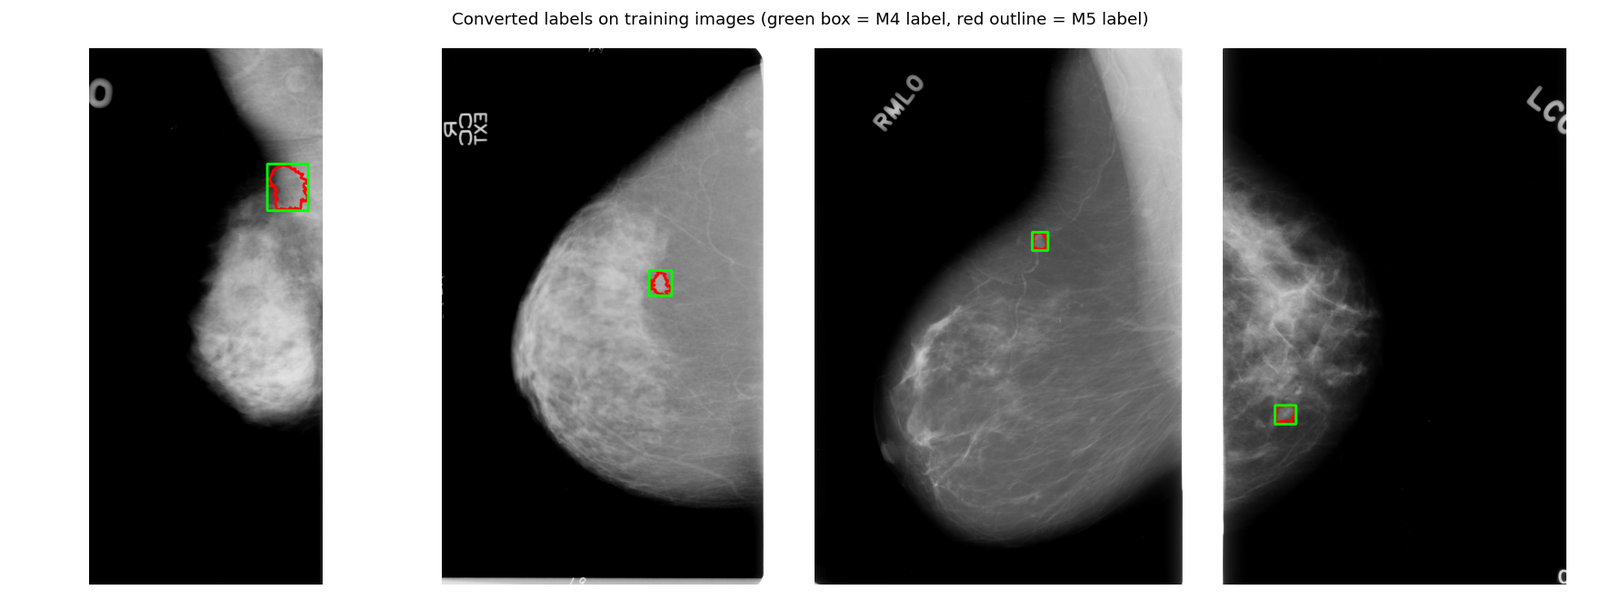

In [6]:
from IPython.display import Image, display
display(Image(filename=str(PROJ / 'figures' / 'label_check.png')))

## 4. Detection (M4): fine-tune YOLO11n, choose the operating point on validation, test once

In [7]:
from ultralytics import YOLO
def train(kind, yaml, model, name):
    best = PROJ / kind / 'runs' / name / 'weights' / 'best.pt'
    if not best.exists():
        YOLO(model).train(data=str(yaml), imgsz=CFG['imgsz'], epochs=CFG['epochs'], batch=CFG['batch'], device=DEV, seed=SEED, patience=5,
                          project=str(PROJ / kind / 'runs'), name=name, exist_ok=True, plots=True, verbose=False,
                          degrees=0.0, flipud=0.5, fliplr=0.5, mosaic=1.0, close_mosaic=3, hsv_h=0.0, hsv_s=0.0, hsv_v=0.3, workers=4)
    return best
# pretrained COCO detector before fine-tuning (baseline for "before training")
if 'm4_before' not in R:
    m0 = YOLO(CFG['seg_model']).val(data=str(SEG_YAML), split='val', imgsz=CFG['imgsz'], device=DEV, verbose=False, plots=False, single_cls=True)
    R['m4_before'] = dict(map50=float(m0.box.map50), map=float(m0.box.map)); R['m5_before'] = dict(mask_map50=float(m0.seg.map50), mask_map=float(m0.seg.map)); save()
# one YOLO11n-seg model gives both the boxes (M4) and the outlines (M5)
DET_BEST = train('segmentation', SEG_YAML, CFG['seg_model'], 'yolo11n_seg_640')
det = YOLO(str(DET_BEST))
hist = pd.read_csv(DET_BEST.parent.parent / 'results.csv'); hist.columns = [c.strip() for c in hist.columns]
R['m4_history'] = hist[['epoch', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']].round(4).values.tolist()
v = det.val(data=str(SEG_YAML), split='val', imgsz=CFG['imgsz'], device=DEV, verbose=False, plots=False)
R['m4_val'] = dict(map50=float(v.box.map50), map=float(v.box.map), best_epoch=int(hist['metrics/mAP50-95(B)'].idxmax() + 1)); save()

def gt_boxes(split, stem, W, H):
    out = []
    for l in (YD / 'labels_det' / split / f'{stem}.txt').read_text().splitlines():
        _, cx, cy, bw, bh = map(float, l.split()); out.append([(cx - bw / 2) * W, (cy - bh / 2) * H, (cx + bw / 2) * W, (cy + bh / 2) * H])
    return np.array(out).reshape(-1, 4)
def iou(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1]); x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None); ar = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (ar(a)[:, None] + ar(b)[None, :] - inter + 1e-9)
def predict_split(model, split, conf=0.05):
    out = []
    for p in sorted((YD / 'images' / split).glob('*.jpg')):
        r = model.predict(str(p), imgsz=CFG['imgsz'], conf=conf, device=DEV, verbose=False)[0]; H, W = r.orig_shape
        out.append(dict(stem=p.stem, W=W, H=H, gt=gt_boxes(split, p.stem, W, H), boxes=r.boxes.xyxy.cpu().numpy(), scores=r.boxes.conf.cpu().numpy(), res=r))
    return out
def pr_at(preds, conf, thr=CFG['match_iou']):
    tp = fp = fn = 0; per = []
    for d in preds:
        k = d['scores'] >= conf; b = d['boxes'][k]; o = np.argsort(-d['scores'][k]); b = b[o]; m = iou(b, d['gt']); used = set(); t = 0
        for i in range(len(b)):
            j = int(np.argmax(m[i])) if m.shape[1] else -1
            if j >= 0 and m[i, j] >= thr and j not in used: used.add(j); t += 1
        tp += t; fp += len(b) - t; fn += len(d['gt']) - len(used); per.append(dict(stem=d['stem'], tp=t, fp=len(b) - t, fn=len(d['gt']) - len(used)))
    P = tp / max(tp + fp, 1); Rc = tp / max(tp + fn, 1)
    return dict(conf=conf, precision=P, recall=Rc, f1=2 * P * Rc / max(P + Rc, 1e-9), f2=5 * P * Rc / max(4 * P + Rc, 1e-9), fppi=fp / len(preds), tp=tp, fp=fp, fn=fn), per
val_preds = predict_split(det, 'val')
sweep = pd.DataFrame([pr_at(val_preds, c)[0] for c in CFG['conf_grid']])
op = sweep.loc[sweep.f2.idxmax()]; CONF_OP = float(op.conf)
R['m4_sweep'] = sweep.round(4).to_dict('records'); R['m4_op'] = dict(conf=CONF_OP, rule='max F2 on validation (recall weighted twice precision)', match_iou=CFG['match_iou']); save()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(sweep.conf, sweep.precision, label='precision'); ax[0].plot(sweep.conf, sweep.recall, label='recall'); ax[0].plot(sweep.conf, sweep.f2, label='F2'); ax[0].axvline(CONF_OP, ls='--', c='k')
ax[0].set_xlabel('confidence threshold'); ax[0].legend(); ax[0].set_title('Validation, 640 px, IoU 0.3')
ax[1].plot(sweep.fppi, sweep.recall, marker='o'); ax[1].set_xlabel('false positives per image'); ax[1].set_ylabel('sensitivity'); ax[1].set_title('FROC-style curve (validation)')
plt.tight_layout(); plt.savefig(PROJ / 'figures' / 'm4_threshold_sweep.png', dpi=110); plt.close()
# test, evaluated once
if 'm4_test' not in R:
    t = det.val(data=str(SEG_YAML), split='test', imgsz=CFG['imgsz'], device=DEV, verbose=False, plots=False)
    test_preds = predict_split(det, 'test'); res, per = pr_at(test_preds, CONF_OP)
    # sensitivity by lesion size (tertiles of the box side at 640 px)
    rows = []
    for d in test_preds:
        k = d['scores'] >= CONF_OP; m = iou(d['gt'], d['boxes'][k])
        for i, g in enumerate(d['gt']):
            rows.append(dict(side=math.sqrt((g[2] - g[0]) * (g[3] - g[1])) * CFG['imgsz'] / max(d['W'], d['H']), hit=bool(m.shape[1] and m[i].max() >= CFG['match_iou'])))
    lr = pd.DataFrame(rows); lr['size'] = pd.qcut(lr.side, 3, labels=['small', 'medium', 'large'])
    bysize = lr.groupby('size', observed=True).agg(n=('hit', 'size'), recall=('hit', 'mean'), side_px=('side', 'median')).round(3).reset_index()
    boot = [pr_at([test_preds[i] for i in np.random.randint(0, len(test_preds), len(test_preds))], CONF_OP)[0]['recall'] for _ in range(300)]
    R['m4_test'] = dict(map50=float(t.box.map50), map=float(t.box.map), **{k: float(v) for k, v in res.items()}, recall_ci95=[float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))],
                        by_size=bysize.to_dict('records'), n_images=len(test_preds)); save()
    pd.DataFrame(per).to_csv(PROJ / 'detection' / 'test_per_image.csv', index=False)
    # error analysis: false positives / misses gallery
    fpi = sorted(test_preds, key=lambda d: -int((d['scores'] >= CONF_OP).sum() - len(d['gt'])))[:3]
    fni = [d for d in test_preds if pr_at([d], CONF_OP)[0]['fn'] > 0][:3]
    fig, ax = plt.subplots(1, 6, figsize=(24, 7))
    for a, d, ttl in zip(ax, fpi + fni, ['most false positives'] * 3 + ['missed mass'] * 3):
        im = cv2.cvtColor(d['res'].orig_img, cv2.COLOR_BGR2RGB).copy()
        for g in d['gt']: cv2.rectangle(im, tuple(map(int, g[:2])), tuple(map(int, g[2:])), (0, 255, 0), 5)
        for b, s in zip(d['boxes'], d['scores']):
            if s >= CONF_OP: cv2.rectangle(im, tuple(map(int, b[:2])), tuple(map(int, b[2:])), (255, 0, 0), 5)
        a.imshow(im); a.set_title(ttl); a.axis('off')
    plt.suptitle(f'Test, 640 px, conf {CONF_OP}: green = ground truth, red = detection'); plt.tight_layout(); plt.savefig(PROJ / 'figures' / 'm4_errors.png', dpi=100); plt.close()
    # error types
    types = dict(localisation=0, background=0)
    for d in test_preds:
        k = d['scores'] >= CONF_OP; m = iou(d['boxes'][k], d['gt'])
        for i in range(m.shape[0]):
            best = m[i].max() if m.shape[1] else 0
            if best < CFG['match_iou']: types['localisation' if best >= 0.1 else 'background'] += 1
    R['m4_fp_types'] = types; save()
# speed on images
p0 = sorted((YD / 'images' / 'test').glob('*.jpg'))[:20]; det.predict(str(p0[0]), imgsz=CFG['imgsz'], device=DEV, verbose=False); t0 = time.perf_counter()
for p in p0: det.predict(str(p), imgsz=CFG['imgsz'], device=DEV, verbose=False)
R['m4_fps'] = len(p0) / (time.perf_counter() - t0); save()
print(R['m4_val'], R['m4_op'], {k: R['m4_test'][k] for k in ['map50', 'map', 'recall', 'precision', 'fppi']})

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 113 layers, 2,868,664 parameters, 0 gradients, 9.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1033.2±250.4 MB/s, size: 42.8 KB)
val: Scanning /content/data/yolo_seg/labels/val... 199 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 199/199 787.9it/s 0.3s
val: New cache created: /content/data/yolo_seg/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.9it/s 3.4s
                   all        199        216          0          0          0          0          0          0          0          0
Speed: 0.9ms preprocess, 3.9ms inference, 0.0ms loss, 2.3ms postprocess per image
New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 

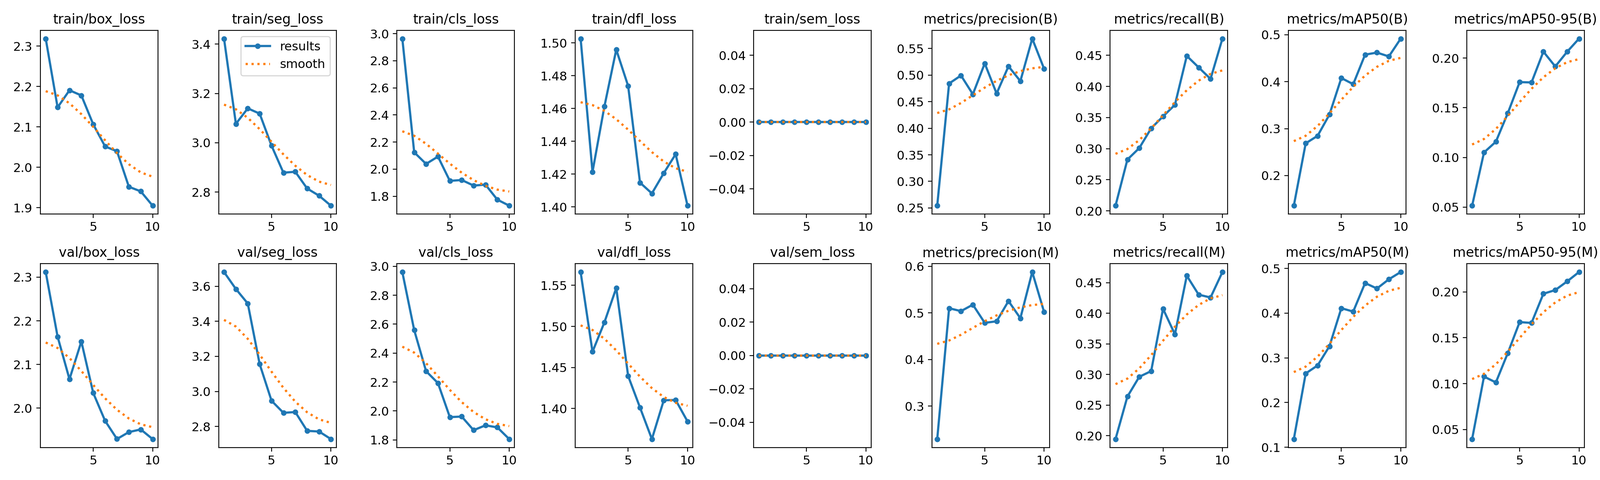

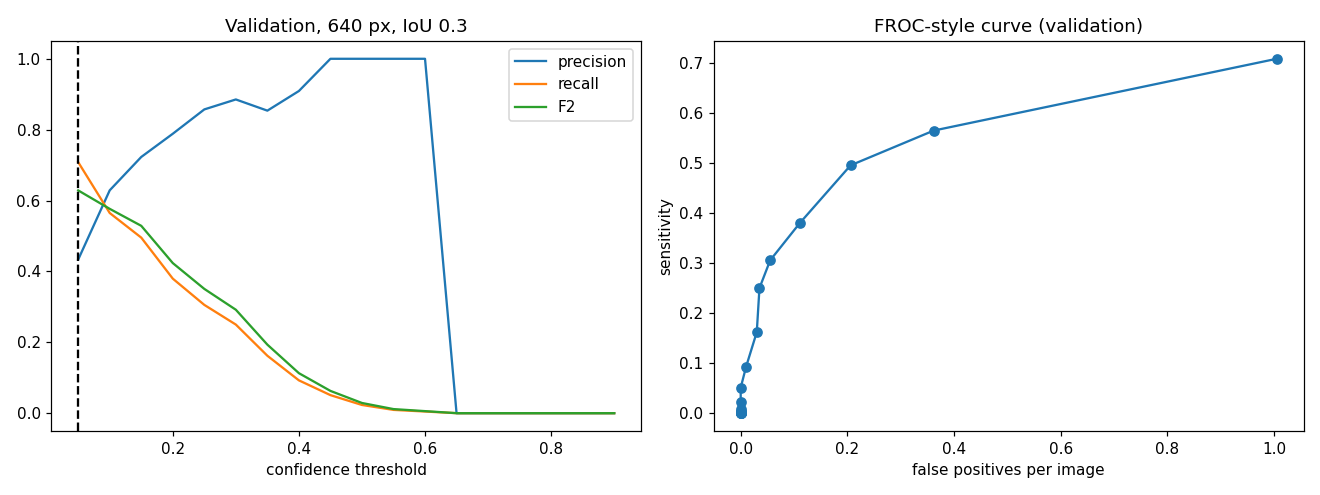

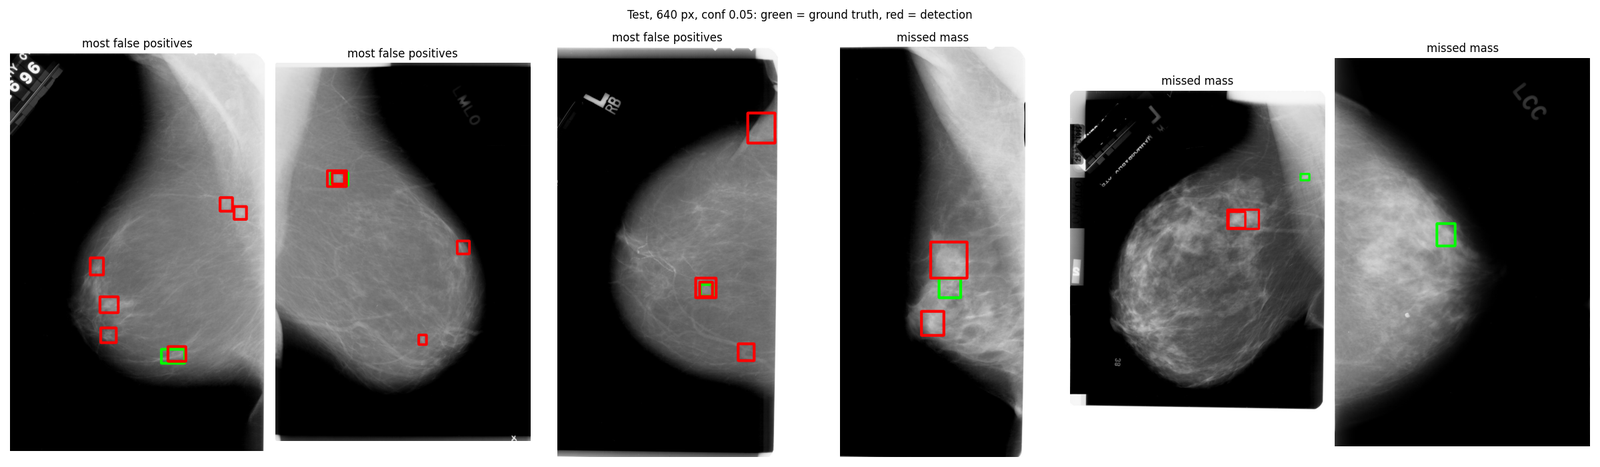

In [8]:
from IPython.display import Image, display
display(Image(filename=str(PROJ / 'figures' / 'training_curves.png')))
display(Image(filename=str(PROJ / 'figures' / 'm4_threshold_sweep.png')))
display(Image(filename=str(PROJ / 'figures' / 'm4_errors.png')))

## 5. Segmentation (M5): masks drawn by radiologists (CBIS-DDSM ROI masks), YOLO11n-seg vs. two baselines

In [9]:
if 'm5_before' not in R:
    m0 = YOLO(CFG['seg_model']).val(data=str(SEG_YAML), split='val', imgsz=CFG['imgsz'], device=DEV, verbose=False, plots=False, single_cls=True)
    R['m5_before'] = dict(mask_map50=float(m0.seg.map50), mask_map=float(m0.seg.map)); save()
SEG_BEST = DET_BEST
seg = det
hs = pd.read_csv(SEG_BEST.parent.parent / 'results.csv'); hs.columns = [c.strip() for c in hs.columns]
R['m5_history'] = hs[['epoch', 'metrics/mAP50(M)', 'metrics/mAP50-95(M)']].round(4).values.tolist()
def gt_mask(split, stem, W, H):
    m = np.zeros((H, W), np.uint8)
    for l in (YD / 'labels_seg' / split / f'{stem}.txt').read_text().splitlines():
        cv2.fillPoly(m, [(np.array(l.split()[1:], float).reshape(-1, 2) * [W, H]).astype(np.int32)], 1)
    return m.astype(bool)
def seg_eval(split, conf):
    I = U = Pi = Gi = 0; dices = []; rows = []
    for p in sorted((YD / 'images' / split).glob('*.jpg')):
        im = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE); H, W = im.shape; g = gt_mask(split, p.stem, W, H)
        r = seg.predict(str(p), imgsz=CFG['imgsz'], conf=conf, device=DEV, verbose=False, retina_masks=True)[0]
        pm = np.zeros((H, W), bool)
        if r.masks is not None: pm = r.masks.data.cpu().numpy().astype(bool).any(0)
        db = det.predict(str(p), imgsz=CFG['imgsz'], conf=CONF_OP, device=DEV, verbose=False)[0].boxes.xyxy.cpu().numpy()
        b0 = np.zeros((H, W), bool); b1 = np.zeros((H, W), bool)
        for x1, y1, x2, y2 in db.astype(int):
            b0[y1:y2, x1:x2] = True
            crop = im[y1:y2, x1:x2]
            if crop.size:
                _, th = cv2.threshold(cv2.GaussianBlur(crop, (5, 5), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU); b1[y1:y2, x1:x2] |= th > 0
        out = {}
        for k, m in [('model', pm), ('B0_boxes', b0), ('B1_otsu_in_box', b1)]:
            i = (m & g).sum(); u = (m | g).sum(); out[k] = (i, u, m.sum(), g.sum())
        rows.append(dict(stem=p.stem, **{f'{k}_dice': 2 * v[0] / max(v[2] + v[3], 1) for k, v in out.items()}, **{f'{k}_iou': v[0] / max(v[1], 1) for k, v in out.items()}))
    df = pd.DataFrame(rows)
    return df
if 'm5_conf' not in R:
    best = None
    for c in [0.1, 0.2, 0.3, 0.4, 0.5]:
        d = seg_eval('val', c); s = d.model_dice.mean()
        if best is None or s > best[1]: best = (c, s)
    R['m5_conf'] = dict(conf=best[0], val_dice=float(best[1])); save()
SEG_CONF = R['m5_conf']['conf']
if 'm5_test' not in R:
    sv = seg.val(data=str(SEG_YAML), split='val', imgsz=CFG['imgsz'], device=DEV, verbose=False, plots=False)
    st = seg.val(data=str(SEG_YAML), split='test', imgsz=CFG['imgsz'], device=DEV, verbose=False, plots=False)
    dv = seg_eval('val', SEG_CONF); dt = seg_eval('test', SEG_CONF); dt.to_csv(PROJ / 'segmentation' / 'test_per_image.csv', index=False)
    R['m5_val'] = dict(mask_map50=float(sv.seg.map50), mask_map=float(sv.seg.map), **{c: float(dv[c].mean()) for c in dv.columns if c != 'stem'})
    R['m5_test'] = dict(mask_map50=float(st.seg.map50), mask_map=float(st.seg.map), **{c: float(dt[c].mean()) for c in dt.columns if c != 'stem'})
    worst = dt.sort_values('model_dice').iloc[0]; R['m5_failure'] = dict(stem=worst.stem, dice=float(worst.model_dice)); save()
    # gallery: best / median / worst
    pick = [dt.sort_values('model_dice').iloc[i] for i in (len(dt) - 1, len(dt) // 2, 0)]
    fig, ax = plt.subplots(1, 3, figsize=(15, 7))
    for a, r_, ttl in zip(ax, pick, ['best', 'median', 'worst']):
        p = YD / 'images' / 'test' / f'{r_.stem}.jpg'; im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB); H, W = im.shape[:2]; g = gt_mask('test', r_.stem, W, H)
        rr = seg.predict(str(p), imgsz=CFG['imgsz'], conf=SEG_CONF, device=DEV, verbose=False, retina_masks=True)[0]
        pm = rr.masks.data.cpu().numpy().astype(bool).any(0) if rr.masks is not None else np.zeros((H, W), bool)
        ov = im.copy(); ov[pm & g] = (0, 200, 0); ov[pm & ~g] = (220, 0, 0); ov[~pm & g] = (0, 80, 255)
        a.imshow(cv2.addWeighted(im, 0.5, ov, 0.5, 0)); a.set_title(f'{ttl}: Dice {r_.model_dice:.2f}'); a.axis('off')
    plt.suptitle(f'Test, 640 px, conf {SEG_CONF}: green = correct, red = extra, blue = missed'); plt.tight_layout(); plt.savefig(PROJ / 'figures' / 'm5_gallery.png', dpi=100); plt.close()
print(R['m5_conf'], {k: round(v, 3) for k, v in R['m5_test'].items()})

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2290.8±624.0 MB/s, size: 58.4 KB)
val: Scanning /content/data/yolo_seg/labels/val.cache... 199 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 199/199 36.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 5.8it/s 2.3s
                   all        199        216      0.513      0.477      0.494       0.22      0.498      0.463      0.486      0.216
Speed: 0.7ms preprocess, 3.6ms inference, 0.0ms loss, 1.9ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 19

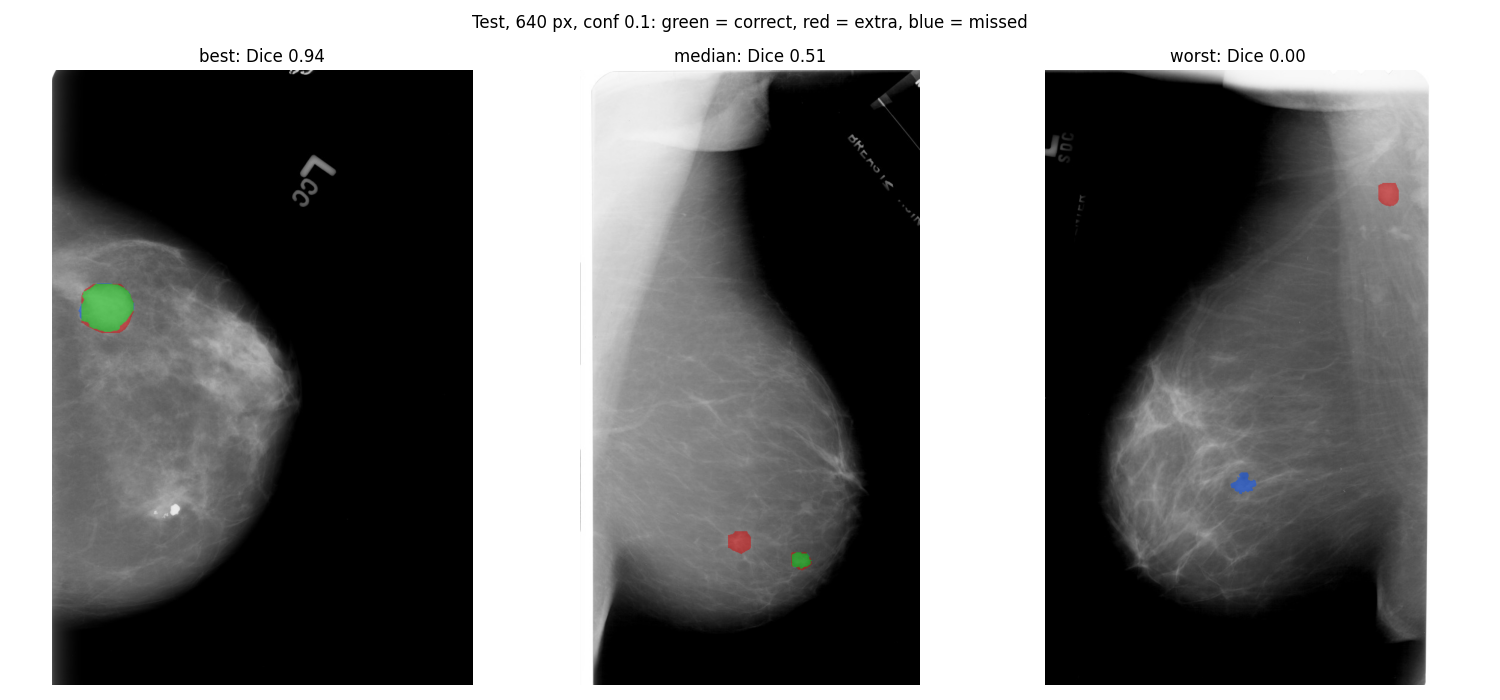

In [10]:
from IPython.display import Image, display
display(Image(filename=str(PROJ / 'figures' / 'm5_gallery.png')))

## 6. Classifier for the pipeline: benign vs. malignant on lesion crops (Phase 1 model retrained at 224 px)
The Phase 1 data-improvement plan asked for a larger input (128 then 224 px) and crops tightened with the ROI masks; this is done here on the same patient-level split.

In [11]:
import torch.nn as nn, torchvision
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
CLSD = PROJ / 'deployment' / 'models'; S = CFG['cls_size']
def lesion_crops(split):
    X, y = [], []
    for _, r in cases[cases.split == split].iterrows():
        m = cv2.imread(r['mask'], cv2.IMREAD_GRAYSCALE) > 127; ys, xs = np.where(m)
        if len(xs) == 0: continue
        x1, x2, y1, y2 = xs.min(), xs.max(), ys.min(), ys.max(); pad = int(0.15 * max(x2 - x1, y2 - y1)) + 8
        im = cv2.imread(r['image'], cv2.IMREAD_GRAYSCALE); H, W = im.shape
        c = im[max(0, y1 - pad):min(H, y2 + pad), max(0, x1 - pad):min(W, x2 + pad)]
        X.append(cv2.resize(c, (S, S), interpolation=cv2.INTER_AREA)); y.append(r['malignant'])
    return np.stack(X), np.array(y)
CC = DATA / 'cls_cache.npz'
if not CC.exists():
    d = {s: lesion_crops(s) for s in ['train', 'val', 'test']}; np.savez_compressed(CC, **{f'{s}_{k}': v for s, (X, y) in d.items() for k, v in zip('Xy', (X, y))})
cz = np.load(CC); XC = {s: (cz[f'{s}_X'], cz[f'{s}_y']) for s in ['train', 'val', 'test']}
dev = torch.device('cuda' if GPU else 'cpu')
def to_t(X, train):
    x = torch.from_numpy(X).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(dev)
    if train:
        if random.random() < 0.5: x = x.flip(3)
        if random.random() < 0.5: x = x.flip(2)
        x = (x * (0.85 + 0.3 * torch.rand(len(x), 1, 1, 1, device=dev))).clamp(0, 1)
    return (x - torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)) / torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)
def probs(m, X):
    m.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), 64): out.append(torch.softmax(m(to_t(X[i:i + 64], False)), 1)[:, 1].cpu().numpy())
    return np.concatenate(out)
CK = CLSD / 'classifier_resnet18.pt'
if not CK.exists():
    m = torchvision.models.resnet18(weights='IMAGENET1K_V1'); m.fc = nn.Linear(512, 2); m.to(dev)
    opt = torch.optim.AdamW(m.parameters(), 1e-4, weight_decay=1e-4); Xtr, ytr = XC['train']; best = -1; hist_c = []
    w = torch.tensor([1.0, (ytr == 0).sum() / max((ytr == 1).sum(), 1)], device=dev).float()
    for ep in range(CFG['cls_epochs']):
        m.train(); idx = np.random.permutation(len(Xtr))
        for i in range(0, len(idx), 32):
            b = idx[i:i + 32]; loss = nn.functional.cross_entropy(m(to_t(Xtr[b], True)), torch.from_numpy(ytr[b]).to(dev), weight=w)
            opt.zero_grad(); loss.backward(); opt.step()
        auc = roc_auc_score(XC['val'][1], probs(m, XC['val'][0])); hist_c.append([ep + 1, float(auc)]); print('epoch', ep + 1, 'val AUC', round(auc, 3))
        if auc > best: best = auc; torch.save(m.state_dict(), CK)
    R['cls_history'] = hist_c
    m0 = torchvision.models.resnet18(weights='IMAGENET1K_V1'); m0.fc = nn.Linear(512, 2); m0.to(dev)
    R['cls_before'] = dict(val_auc=float(roc_auc_score(XC['val'][1], probs(m0, XC['val'][0])))); save()
cls = torchvision.models.resnet18(); cls.fc = nn.Linear(512, 2); cls.load_state_dict(torch.load(CK, map_location=dev)); cls.to(dev)
if 'cls_test' not in R:
    pv = probs(cls, XC['val'][0]); pt = probs(cls, XC['test'][0])
    ths = np.linspace(0.05, 0.95, 19); thr = float(ths[np.argmax([balanced_accuracy_score(XC['val'][1], pv >= t) for t in ths])])
    bs = [roc_auc_score(XC['test'][1][i], pt[i]) for i in [np.random.randint(0, len(pt), len(pt)) for _ in range(500)] if len(set(XC['test'][1][i])) > 1]
    R['cls_val'] = dict(auc=float(roc_auc_score(XC['val'][1], pv)), threshold=thr)
    R['cls_test'] = dict(auc=float(roc_auc_score(XC['test'][1], pt)), auc_ci95=[float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))],
                         bal_acc=float(balanced_accuracy_score(XC['test'][1], pt >= thr)), n=int(len(pt)), phase1_test_auc=0.751); save()
print(R.get('cls_before'), R['cls_val'], R['cls_test'])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 27.5MB/s]


epoch 1 val AUC 0.738
epoch 2 val AUC 0.771
epoch 3 val AUC 0.762
epoch 4 val AUC 0.794
epoch 5 val AUC 0.775
epoch 6 val AUC 0.765
{'val_auc': 0.423053501522401} {'auc': 0.7940843845150065, 'threshold': 0.35} {'auc': 0.7805459097149317, 'auc_ci95': [0.7290386685513437, 0.8325703991130821], 'bal_acc': 0.703807639505774, 'n': 325, 'phase1_test_auc': 0.751}


## 7. System integration (M8): ONNX export with parity checks, manifest, HTTP service, benchmark, verdict

In [12]:
import onnxruntime as ort
MD = PROJ / 'deployment' / 'models'
for name, mdl in [('segmenter', seg)]:
    if not (MD / f'{name}.onnx').exists():
        p = mdl.export(format='onnx', imgsz=CFG['imgsz'], opset=17, simplify=True, dynamic=False); shutil.copy(p, MD / f'{name}.onnx')
if not (MD / 'classifier.onnx').exists():
    cls.eval().cpu(); torch.onnx.export(cls, torch.randn(1, 3, S, S), str(MD / 'classifier.onnx'), input_names=['images'], output_names=['logits'], opset_version=17,
                                        dynamic_axes={'images': {0: 'batch'}, 'logits': {0: 'batch'}}); cls.to(dev)
# parity: detections PyTorch vs ONNX on 20 val images; classifier logits on 64 val crops
det_onnx = seg_onnx = YOLO(str(MD / 'segmenter.onnx'), task='segment')
agree = []; vimgs = sorted((YD / 'images' / 'val').glob('*.jpg'))[:20]
for p in vimgs:
    a = det.predict(str(p), imgsz=CFG['imgsz'], conf=CONF_OP, device='cpu', verbose=False)[0].boxes.xyxy.numpy()
    b = det_onnx.predict(str(p), imgsz=CFG['imgsz'], conf=CONF_OP, device='cpu', verbose=False)[0].boxes.xyxy.numpy()
    agree.append(1.0 if len(a) == len(b) == 0 else float((iou(a, b).max(1) >= 0.9).mean()) if len(a) and len(b) else 0.0)
so = ort.InferenceSession(str(MD / 'classifier.onnx')); Xp = XC['val'][0][:64]
with torch.no_grad(): lt = cls.cpu()(to_t(Xp, False).cpu()).numpy()
cls.to(dev); lo = so.run(None, {'images': to_t(Xp, False).cpu().numpy()})[0]
R['m8_parity'] = dict(det_same_decisions=float(np.mean(agree)), cls_max_abs=float(np.abs(lt - lo).max()), cls_argmax_agree=float((lt.argmax(1) == lo.argmax(1)).mean())); save()
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
MAN = dict(name='KHALAF Team CBIS-DDSM mass pipeline', version=time.strftime('%Y.%m.%d'),
           models=dict(
                       segmenter=dict(file='../models/segmenter.onnx', sha256=sha(MD / 'segmenter.onnx'), imgsz=CFG['imgsz'], classes=['mass']),
                       classifier=dict(file='../models/classifier.onnx', sha256=sha(MD / 'classifier.onnx'), imgsz=S, classes=['benign', 'malignant'],
                                       mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], crop_pad=0.15)),
           thresholds=dict(det_conf=CONF_OP, seg_conf=SEG_CONF, malignant_threshold=R['cls_val']['threshold']),
           limits=dict(max_upload_mb=30, min_side_px=64), versions=R['env'], intended_use='Academic exercise only; not for diagnosis, screening or triage.')
SV = PROJ / 'deployment' / 'service'; (SV / 'manifest.json').write_text(json.dumps(MAN, indent=1))
(SV / 'pipeline.py').write_text(r'''
import json, time, hashlib
from pathlib import Path
import numpy as np, cv2, onnxruntime as ort
from ultralytics import YOLO
class Pipeline:
    def __init__(self, d='.'):
        self.d = Path(d); self.m = json.loads((self.d / 'manifest.json').read_text()); t0 = time.perf_counter(); self.checks = {}
        for k, v in self.m['models'].items():
            ok = hashlib.sha256((self.d / v['file']).read_bytes()).hexdigest() == v['sha256']; self.checks[f'{k}_sha256_ok'] = ok
            if not ok: raise RuntimeError(f'checksum mismatch: {k}')
        self.seg = YOLO(str(self.d / self.m['models']['segmenter']['file']), task='segment')
        self.cls = ort.InferenceSession(str(self.d / self.m['models']['classifier']['file']), providers=['CPUExecutionProvider'])
        self.T = self.m['thresholds']; c = self.m['models']['classifier']; self.mean = np.array(c['mean'], np.float32).reshape(1, 3, 1, 1); self.std = np.array(c['std'], np.float32).reshape(1, 3, 1, 1)
        out = self.run(np.full((800, 600), 90, np.uint8)); self.checks['self_test_ok'] = all(k in out for k in ['masses', 'n_masses', 'timings_ms']); self.checks['startup_s'] = round(time.perf_counter() - t0, 2)
    def run(self, gray):
        t = {}; T0 = time.perf_counter(); img = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR) if gray.ndim == 2 else gray; g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        H, W = g.shape; sz = self.m['models']['segmenter']['imgsz']
        s = time.perf_counter(); rs = self.seg.predict(img, imgsz=sz, conf=min(self.T['det_conf'], self.T['seg_conf']), device='cpu', verbose=False, retina_masks=True)[0]
        k = rs.boxes.conf.numpy() >= self.T['det_conf']; boxes = rs.boxes.xyxy.numpy()[k]; scores = rs.boxes.conf.numpy()[k]
        masks = rs.masks.data.numpy().astype(bool)[rs.boxes.conf.numpy() >= self.T['seg_conf']] if rs.masks is not None else np.zeros((0, H, W), bool); t['detector_segmenter'] = time.perf_counter() - s
        s = time.perf_counter(); S = self.m['models']['classifier']['imgsz']; crops = []
        for x1, y1, x2, y2 in boxes.astype(int):
            p = int(0.15 * max(x2 - x1, y2 - y1)) + 8; c = g[max(0, y1 - p):min(H, y2 + p), max(0, x1 - p):min(W, x2 + p)]
            crops.append(cv2.resize(c if c.size else g, (S, S)))
        pm = np.zeros(len(boxes))
        if crops:
            x = (np.repeat(np.stack(crops)[:, None].astype(np.float32) / 255, 3, 1) - self.mean) / self.std
            lg = self.cls.run(None, {'images': x})[0]; e = np.exp(lg - lg.max(1, keepdims=True)); pm = (e / e.sum(1, keepdims=True))[:, 1]
        t['classifier'] = time.perf_counter() - s
        out = []
        for i, (b, sc) in enumerate(zip(boxes, scores)):
            area = None
            if len(masks):
                ov = [(m[int(b[1]):int(b[3]), int(b[0]):int(b[2])]).sum() for m in masks]; j = int(np.argmax(ov))
                if ov[j] > 0: area = int(masks[j].sum())
            out.append(dict(box_xyxy=[round(float(v), 1) for v in b], score=round(float(sc), 3), p_malignant=round(float(pm[i]), 3),
                            label='malignant' if pm[i] >= self.T['malignant_threshold'] else 'benign', mask_area_px=area))
        tm = {k: round(1000 * v, 1) for k, v in t.items()}; tm['total'] = round(1000 * (time.perf_counter() - T0), 1)
        return dict(image_size=dict(width=W, height=H), n_masses=len(out), masses=out, thresholds=self.T, timings_ms=tm,
                    note='Academic exercise only; not for diagnosis, screening or triage.')
''')
(SV / 'app.py').write_text(r'''
import os, cv2, numpy as np
from fastapi import FastAPI, UploadFile, File, HTTPException
from pipeline import Pipeline
P = {}
app = FastAPI(title='CBIS-DDSM mass pipeline (academic)')
@app.on_event('startup')
def load(): P['p'] = Pipeline(os.environ.get('RELEASE_DIR', '.'))
@app.get('/health')
def health(): return dict(status='ok', checks=P['p'].checks, thresholds=P['p'].T)
@app.post('/predict')
async def predict(file: UploadFile = File(...)):
    b = await file.read(); lim = P['p'].m['limits']
    if not b: raise HTTPException(400, 'empty file')
    if len(b) > lim['max_upload_mb'] * 1024 * 1024: raise HTTPException(413, 'file too large')
    im = cv2.imdecode(np.frombuffer(b, np.uint8), cv2.IMREAD_GRAYSCALE)
    if im is None: raise HTTPException(400, 'not a decodable image (JPEG/PNG expected)')
    if min(im.shape) < lim['min_side_px']: raise HTTPException(400, 'image too small')
    return P['p'].run(im)
''')
(SV / 'requirements.txt').write_text('ultralytics==8.4.215\nonnxruntime\nfastapi\nuvicorn\npython-multipart\nopencv-python-headless\nnumpy\n')
(SV / 'README.md').write_text('# CBIS-DDSM mass pipeline (academic)\n\n```bash\npip install -r requirements.txt\nRELEASE_DIR=. uvicorn app:app --port 8000\ncurl -X POST -F "file=@mammogram.jpg" http://localhost:8000/predict\n```\nNot for diagnosis, screening or triage.\n')
import requests
env = dict(os.environ, RELEASE_DIR=str(SV)); srv = subprocess.Popen([sys.executable, '-m', 'uvicorn', 'app:app', '--port', '8000'], cwd=str(SV), env=env, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(180):
    try:
        if requests.get('http://localhost:8000/health', timeout=2).ok: break
    except Exception: time.sleep(1)
R['m8_health'] = requests.get('http://localhost:8000/health').json()
bad = {'empty file': b'', 'text file': b'hello', 'tiny image': cv2.imencode('.png', np.zeros((10, 10), np.uint8))[1].tobytes()}
R['m8_invalid'] = {k: requests.post('http://localhost:8000/predict', files={'file': ('x', v)}).status_code for k, v in bad.items()}
timgs = sorted((YD / 'images' / 'test').glob('*.jpg'))[:33]; lat = []; stages = []
for i, p in enumerate(timgs):
    t0 = time.perf_counter(); j = requests.post('http://localhost:8000/predict', files={'file': (p.name, p.read_bytes(), 'image/jpeg')}).json(); dt = 1000 * (time.perf_counter() - t0)
    if i >= 3: lat.append(dt); stages.append(j['timings_ms'])
R['m8_example'] = j; st = pd.DataFrame(stages)
R['m8_e2e'] = dict(p50=float(np.percentile(lat, 50)), p95=float(np.percentile(lat, 95)), p99=float(np.percentile(lat, 99)), throughput=1000 / float(np.mean(lat)), n=len(lat), hardware='Colab CPU (service), ONNX Runtime')
R['m8_stages'] = {c: dict(p50=float(st[c].median()), p95=float(st[c].quantile(0.95))) for c in st.columns}
import psutil; R['m8_memory_mb'] = psutil.Process(srv.pid).memory_info().rss / 1e6
# model-level benchmark (ONNX Runtime CPU, detector, batch 1)
sess = ort.InferenceSession(str(MD / 'segmenter.onnx'), providers=['CPUExecutionProvider']); x = np.random.rand(1, 3, CFG['imgsz'], CFG['imgsz']).astype(np.float32); nm = sess.get_inputs()[0].name
for _ in range(5): sess.run(None, {nm: x})
tt = []
for _ in range(30): t0 = time.perf_counter(); sess.run(None, {nm: x}); tt.append(1000 * (time.perf_counter() - t0))
R['m8_bench_det_ort_cpu'] = dict(p50=float(np.percentile(tt, 50)), p95=float(np.percentile(tt, 95)), p99=float(np.percentile(tt, 99)), throughput=1000 / float(np.mean(tt)))
srv.terminate(); save()
# verdict
meas = dict(det_recall_op=R['m4_test']['recall'], det_fppi_op=R['m4_test']['fppi'], det_map50=R['m4_test']['map50'], seg_dice=R['m5_test']['model_dice'],
            cls_auc=R['cls_test']['auc'], e2e_p95_ms=R['m8_e2e']['p95'])
ver = [dict(**c, measured=round(meas[c['metric']], 3), passed=bool(meas[c['metric']] >= c['thr'] if c['op'] == '>=' else meas[c['metric']] <= c['thr'])) for c in CRIT]
R['m8_verdict'] = ver; R['m8_decision'] = 'GO' if all(v['passed'] for v in ver) else 'NO-GO'; save()
print(pd.DataFrame(ver)[['id', 'name', 'thr', 'measured', 'passed']], '\nDecision:', R['m8_decision'])

/tmp/ipykernel_486/3627424348.py:7: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  cls.eval().cpu(); torch.onnx.export(cls, torch.randn(1, 3, S, S), str(MD / 'classifier.onnx'), input_names=['images'], output_names=['logits'], opset_version=17,
W1122 16:57:10.909000 486 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Loading /content/drive/MyDrive/capston/KHALAF_CBIS_Phase2/deployment/models/segmenter.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider
   id                                       name      thr  measured  passed
0  C1  Mass detection sensitivity (lesion level)     0.80     0.686   False
1  C2                  False positives per image     1.00     0.865    True
2  C3                            Detection mAP50     0.60     0.504   False
3  C4     Mass segmentation Dice (lesion pixels)     0.70     0.426   False
4  C5   Benign/malignant ROC-AUC on lesion crops     0.75     0.781    True
5  C6           End-to-end p95 latency per image  1500.00   920.496    True 
Decision: NO-GO


## 8. Before, during and after training (summary figure)

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
h = np.array(R['m4_history']); ax[0].plot(h[:, 0], h[:, 1], 'b-o', ms=3); ax[0].scatter([0], [R['m4_before']['map50']], c='r', s=60, zorder=5); ax[0].scatter([h[-1, 0] + 1], [R['m4_test']['map50']], marker='*', c='g', s=200, zorder=5)
ax[0].set_title('Detector: mAP50'); ax[0].set_xlabel('epoch')
h = np.array(R['m5_history']); ax[1].plot(h[:, 0], h[:, 2], 'b-o', ms=3); ax[1].scatter([0], [R['m5_before']['mask_map']], c='r', s=60, zorder=5); ax[1].scatter([h[-1, 0] + 1], [R['m5_test']['mask_map']], marker='*', c='g', s=200, zorder=5)
ax[1].set_title('Segmenter: mask mAP50-95'); ax[1].set_xlabel('epoch')
h = np.array(R['cls_history']); ax[2].plot(h[:, 0], h[:, 1], 'b-o', ms=3); ax[2].scatter([0], [R['cls_before']['val_auc']], c='r', s=60, zorder=5); ax[2].scatter([h[-1, 0] + 1], [R['cls_test']['auc']], marker='*', c='g', s=200, zorder=5)
ax[2].set_title('Classifier: ROC-AUC'); ax[2].set_xlabel('epoch')
for a in ax: a.grid(alpha=0.3)
plt.suptitle('Red dot: before training (pretrained) | blue: validation after each epoch | green star: final model on test'); plt.tight_layout(); plt.savefig(PROJ / 'figures' / 'training_summary.png', dpi=120); plt.close()
for src, dst in [(DET_BEST.parent.parent / 'results.png', 'training_curves.png')]:
    if src.exists(): shutil.copy(src, PROJ / 'figures' / dst)
print('ALL_DONE', R['m8_decision'])

ALL_DONE NO-GO


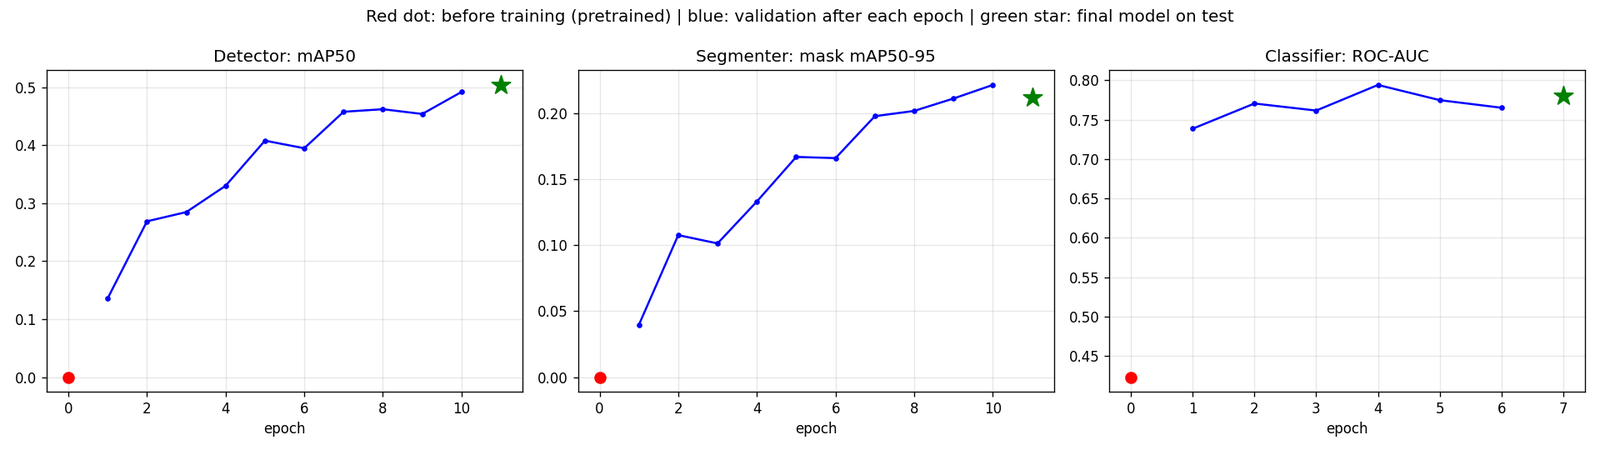

In [14]:
from IPython.display import Image, display
display(Image(filename=str(PROJ / 'figures' / 'training_summary.png')))

## 9. Mask audit sample (100 random masses) and package versions
Automatic checks per mask; the sheet `figures/audit_sheet.png` is for the visual review recorded in `audit_sample.csv`.

In [15]:
c = pd.read_csv(PROJ / 'detection' / 'cases.csv'); s = c.sample(100, random_state=SEED); rows = []
for _, r in s.iterrows():
    m = cv2.imread(r['mask'], cv2.IMREAD_GRAYSCALE) > 127; im = cv2.imread(r['image'], cv2.IMREAD_GRAYSCALE)
    n, _ = cv2.connectedComponents(m.astype(np.uint8)); n -= 1
    area = m.mean(); inside = float((im[m] > 20).mean()) if m.any() else 0.0
    ys, xs = np.where(m); fill = m.sum() / max((xs.max() - xs.min() + 1) * (ys.max() - ys.min() + 1), 1) if m.any() else 0
    ok = n >= 1 and 0.00005 < area < 0.2 and inside > 0.95
    rows.append(dict(row_key=f"mass_{r['patient']}_{r['side']}_{r['view']}_{r['abn']}_{r['split']}", split=r['split'], pathology=r['pathology'],
                     image_series=Path(r['image']).parent.name, mask_series=Path(r['mask']).parent.name, mask_parts=int(n), mask_area_pct=round(100 * area, 3),
                     mask_fill_of_box=round(float(fill), 3), mask_on_breast_pct=round(100 * inside, 1), auto_check='pass' if ok else 'flag',
                     visual_review='', note='', reviewer='', review_date=''))
a = pd.DataFrame(rows); a.to_csv(PROJ / 'audit_sample.csv', index=False); print(a.auto_check.value_counts(), a.mask_parts.value_counts().to_dict())
# visual sheet of the 100 sampled masks for the team's review
fig, ax = plt.subplots(10, 10, figsize=(20, 22))
for a_, (_, r) in zip(ax.ravel(), s.iterrows()):
    im = cv2.imread(r['image'], cv2.IMREAD_GRAYSCALE); m = cv2.imread(r['mask'], cv2.IMREAD_GRAYSCALE) > 127
    ys, xs = np.where(m); p = 60; y1, y2, x1, x2 = max(0, ys.min() - p), ys.max() + p, max(0, xs.min() - p), xs.max() + p
    cr = cv2.cvtColor(im[y1:y2, x1:x2], cv2.COLOR_GRAY2RGB); cs, _ = cv2.findContours(m[y1:y2, x1:x2].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(cr, cs, -1, (255, 0, 0), max(2, cr.shape[0] // 150)); a_.imshow(cr); a_.set_title(r['patient'], fontsize=7); a_.axis('off')
plt.tight_layout(); plt.savefig(PROJ / 'figures' / 'audit_sheet.png', dpi=60); plt.close()
sh(f'{sys.executable} -m pip freeze > {PROJ}/pip_freeze.txt')
print('EXTRA_DONE')

auto_check
pass    96
flag     4
Name: count, dtype: int64 {3: 19, 1: 16, 2: 14, 4: 10, 6: 10, 5: 9, 7: 5, 9: 4, 8: 3, 20: 2, 12: 2, 10: 2, 16: 1, 17: 1, 13: 1, 14: 1}
$ /usr/bin/python3 -m pip freeze > /content/drive/MyDrive/capston/KHALAF_CBIS_Phase2/pip_freeze.txt
EXTRA_DONE


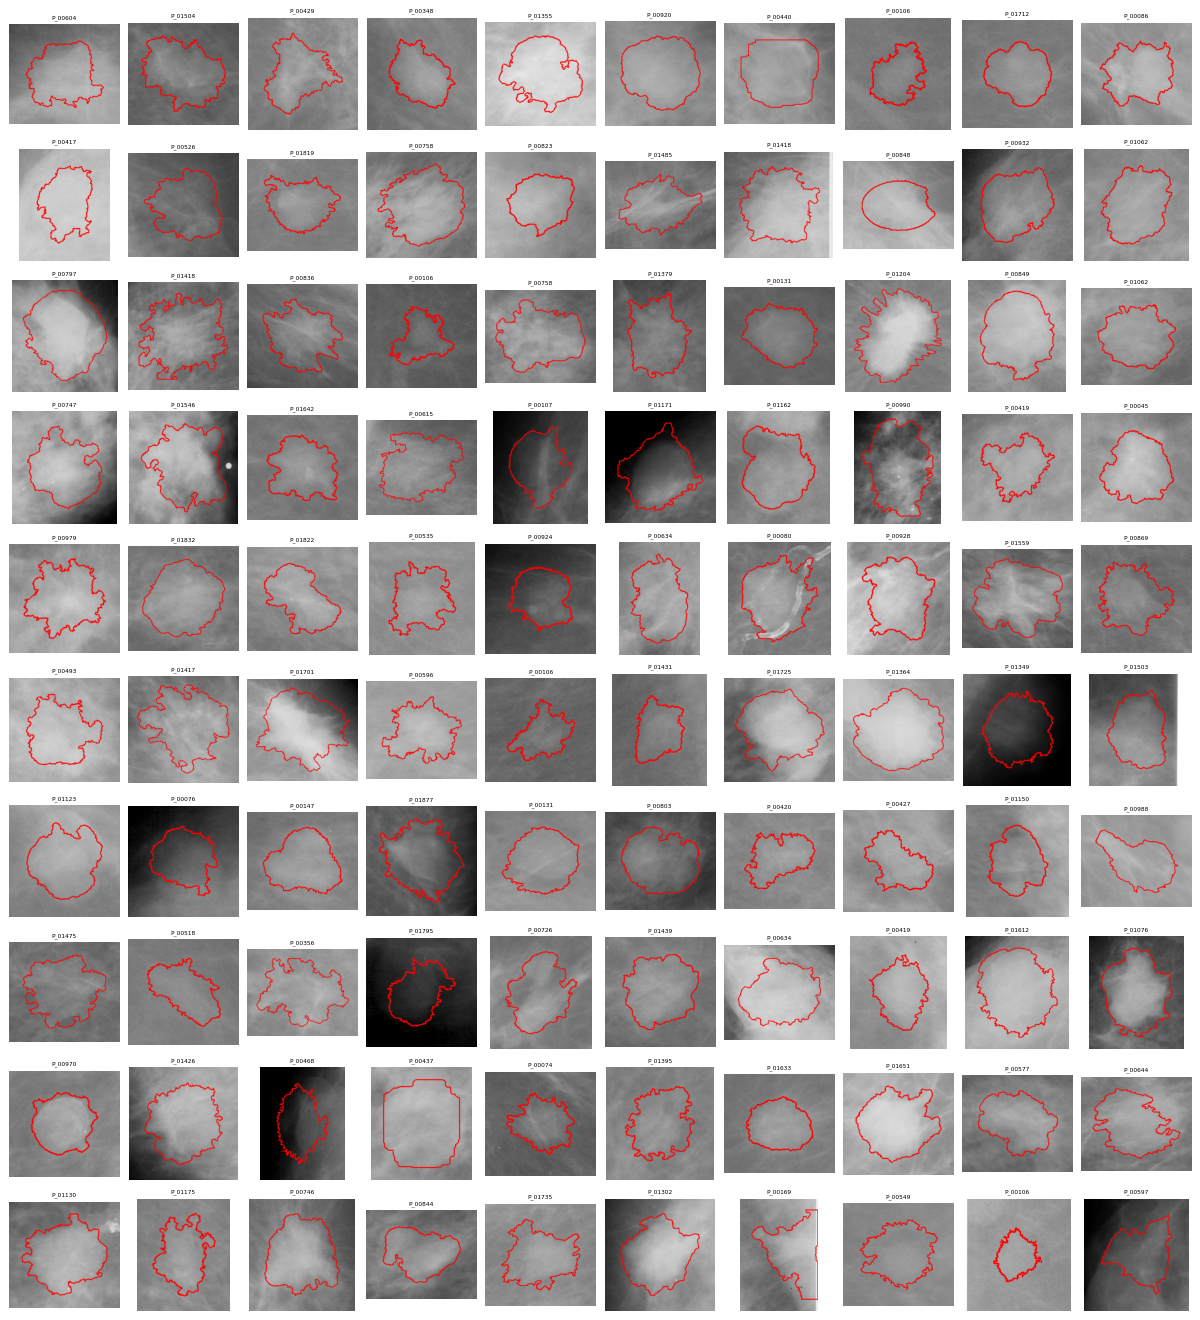

In [16]:
from IPython.display import Image, display
display(Image(filename=str(PROJ / 'figures' / 'audit_sheet.png')))